# PRÁCTICA: LOS DOMINIOS DE ATRACCIÓN

## Manuel Cantero Ruiz

## 1.Representación Gráfica

In [1]:
import numpy as np
import matplotlib.pyplot as plt

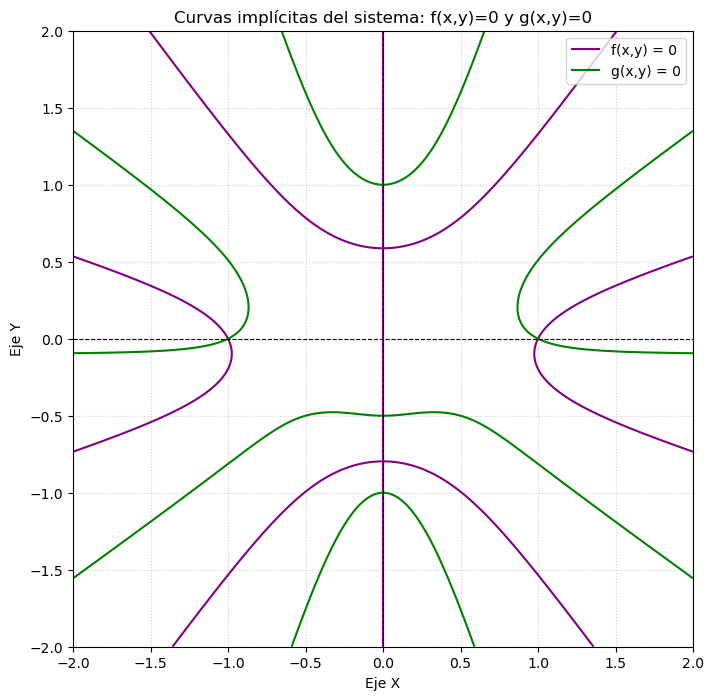

In [2]:
# Definimos las funciones f(x,y) y g(x,y)

def f(x, y):
    return 2*x**5 - 20*x**3*y**2 - 4*x**3*y + 10*x*y**4 + 4*x*y**3 - 2*x

def g(x, y):
    return 10*x**4*y + x**4 - 20*x**2*y**3 - 6*x**2*y**2 + 2*y**5 + y**4 - 2*y - 1

# Creamos el cuadrado de 400 x 400 puntos en el dominio [-2, 2] x [-2, 2]
x_vals = np.linspace(-2.0, 2.0, 400)
y_vals = np.linspace(-2.0, 2.0, 400)
X, Y = np.meshgrid(x_vals, y_vals)

# Evaluamos las funciones en la malla
F_vals = f(X, Y)
G_vals = g(X, Y)

# Configuramos la gráfica
plt.figure(figsize=(8, 8))
plt.title("Curvas implícitas del sistema: f(x,y)=0 y g(x,y)=0")

# Dibujamos f(x,y) = 0 y g(x,y) = 0 con distintos colores
# Con la función contour(X, Y, Z, levels) -> levels=[0] dibujamos solo las curvas (Z=0)

plt.contour(X, Y, F_vals, levels=[0], colors='purple', linewidths=1.5)
plt.contour(X, Y, G_vals, levels=[0], colors='green', linewidths=1.5)

# Añadimos detalles extras a la gráfica y una leyenda

plt.xlim([-2, 2])
plt.ylim([-2, 2])
plt.axhline(0, color='black', linewidth=0.8, linestyle='--') # Eje X
plt.axvline(0, color='black', linewidth=0.8, linestyle='--') # Eje Y
plt.grid(True, linestyle=':', alpha=0.6)
plt.xlabel("Eje X")
plt.ylabel("Eje Y")

from matplotlib.lines import Line2D
custom_lines = [Line2D([0], [0], color='purple', lw=1.5),
                Line2D([0], [0], color='green', lw=1.5)]
plt.legend(custom_lines, ['f(x,y) = 0', 'g(x,y) = 0'], loc='upper right')

plt.show()

## 2. Implementación y aplicación del método

In [3]:
# Definimos las funciones de las derivadas parciales manualmente
def df_dx(x, y):
    return 10*x**4 - 60*x**2*y**2 - 12*x**2*y + 10*y**4 + 4*y**3 - 2

def df_dy(x, y):
    return -40*x**3*y - 4*x**3 + 40*x*y**3 + 12*x*y**2

def dg_dx(x, y):
    return 40*x**3*y + 4*x**3 - 40*x*y**3 - 12*x*y**2

def dg_dy(x, y):
    return 10*x**4 - 60*x**2*y**2 - 12*x**2*y + 10*y**4 + 4*y**3 - 2

# Función de la matriz Jacobiana en (x,y)
def jacobiano(x, y):
    return np.array([
        [df_dx(x, y), df_dy(x, y)],
        [dg_dx(x, y), dg_dy(x, y)]
    ])

In [4]:
# Implementacióm del método de Newton-Raphson para resolver el sistema F(x,y)=0
# Recibe el punto inicial, la tolerancia impuesta (criterio de parada) y 
# un número máximo de iteraciones para evitar bucles infinitos si el método diverge
# Devuelve la raíz encontrada y el número de iteraciones realizadas.

def newton_raphson_sistema(x0, y0, tol=1e-5, max_iter=50):

    X = np.array([x0, y0], dtype=float)
    
    for i in range(max_iter):
        x, y = X[0], X[1]
        
        # Evaluamos la función vectorial F(X)
        F = np.array([f(x, y), g(x, y)])
        
        # Condición de parada: comprobamos si la norma de F es menor que la tolerancia impuesta
        if np.linalg.norm(F, np.inf) < tol:
            return X, i
        
        # Evaluamos el Jacobiano
        J = jacobiano(x, y)
        
        # En lugar de calcular explícitamente la inversa del Jacobiano, vamos a resolver el 
        # sistema lineal: J * dX = -F. Siendo más rápido y menos propenso a errores de redondeo.
        # Reorganizando así el paso de actualización de la solución X_{i+1} = X_i - J(X_i)^{-1} F(X_i)
        # resolviendo simplemente dX y aplicando X_{i+1} = X_i + dX.
        
        try:
            dX = np.linalg.solve(J, -F)
        except np.linalg.LinAlgError:
            # Si el Jacobiano es singular (determinante 0), el método falla
            # Podemos mandar un mensaje para avisar de ese error, aunque se ejecutaria muchas veces
            # si en ciertas zonas miles de puntos causan un Jacobiano singular 
            # print(f"Error: Jacobiano singular en la iteración {i}")
            return None, i
            
        # Actualizamos la solución
        X = X + dX
        
        # Segunda condición de parada: si el paso dX es muy pequeño
        if np.linalg.norm(dX, np.inf) < tol:
            return X, i
            
    # Si llega hasta aquí, el método no ha convergido en el número máximo de iteraciones dadas
    return X, max_iter

In [5]:
# Lista de puntos iniciales extraídos visualmente de la gráfica de la Fase 1 (explicación abajo)
# 
puntos_iniciales = [
    (1.2, 0.1),
    (0.2, 0.8),
    (-0.2, -0.6),
    (-1.1, 0.1),
    (0.1, -1.2)
]

soluciones = []

print("Soluciones encontradas con precisión 10^-5...\n")
for idx, (x0, y0) in enumerate(puntos_iniciales):
    raiz, iteraciones = newton_raphson_sistema(x0, y0, tol=1e-5)
    if raiz is not None:
        soluciones.append(raiz)
        print(f"Solución {idx+1}: Converge a (x={raiz[0]:.5f}, y={raiz[1]:.5f}) en {iteraciones} iteraciones. (Punto inicial: {x0}, {y0})")

Soluciones encontradas con precisión 10^-5...

Solución 1: Converge a (x=1.00000, y=-0.00000) en 4 iteraciones. (Punto inicial: 1.2, 0.1)
Solución 2: Converge a (x=-0.00000, y=1.00000) en 6 iteraciones. (Punto inicial: 0.2, 0.8)
Solución 3: Converge a (x=0.00000, y=-0.50000) en 3 iteraciones. (Punto inicial: -0.2, -0.6)
Solución 4: Converge a (x=-1.00000, y=0.00000) en 4 iteraciones. (Punto inicial: -1.1, 0.1)
Solución 5: Converge a (x=0.00000, y=-1.00000) en 4 iteraciones. (Punto inicial: 0.1, -1.2)


¿Por qué estos puntos?

$(1.2, 0.1)$: Está en el primer cuadrante, cercano a la raíz sobre el eje X. 

$(0.2, 0.8)$: Está cerca de la parte superior, el desplazamiento aseguraría las iteraciones claras hacía en la raíz del eje Y positivo.

$(-0.2, -0.6)$: Está cerca del eje Y negativo y apunta a la raíz del tercer cuadrante, pero ligeramente desplazado para evitar singularidades.

$(-1.1, 0.1)$: Buscamos la simétrica de la primera raíz en el lado negativo del eje X.

$(0.1, -1.2)$: Apuntamos hacia la parte inferior del eje Y. Según la estructura de g(x,y), buscamos que sea cercano a la posible raíz cerca de (0, -1).

## 3. Dominios de atracción

In [6]:
from matplotlib.colors import hsv_to_rgb

# Convertimos la lista de soluciones anterior directamente en nuestro array de raíces
# Lo redondeamos a 5 decimales para evitar pequeños residuos numéricos
raices_exactas = np.round(np.array(soluciones), 5)

# Definimos la resolución de la malla (puntos por lado). 
resolucion = 500
x_min, x_max = -2.0, 2.0
y_min, y_max = -2.0, 2.0

# Creamos matrices para almacenar el color (según la raíz) y el tono (iteraciones hasta converger)
mapa_raices = np.zeros((resolucion, resolucion), dtype=int)
mapa_iteraciones = np.zeros((resolucion, resolucion), dtype=int)

# Ejes para recorrer la malla
x_vals = np.linspace(x_min, x_max, resolucion)
y_vals = np.linspace(y_max, y_min, resolucion) # Invertido para que el dibujo de imshow sea correcto

In [7]:
# La función compara el punto encontrado con la lista de raíces exactas y calcula la distancia a
# las 5 raíces exactas conocidas. Devuelve el índice de la raíz más cercana (0 a 4) o -1 si diverge.

def clasificar_raiz(punto_encontrado, raices, tol=1e-3):

    if punto_encontrado is None:
        return -1
    
    # Calculamos la distancia euclídea desde el punto a todas las raíces
    distancias = np.linalg.norm(raices - punto_encontrado, axis=1)
    indice_min = np.argmin(distancias)
    
    # Si la distancia a la raíz más cercana es menor que la tolerancia, confirmamos
    if distancias[indice_min] < tol:
        return indice_min
    return -1

In [8]:
# Recorremos la malla punto a punto ejecutando el método iterativo para cada punto y guardando
# la raíz a la que llega y las iteraciones que ha tardado.

# Puede tardar un poco al igual que antes. (Debe desaparecer * de In [*])

print("Generando el fractal... ")   

# Bucle sobre cada píxel de la imagen
for i in range(resolucion):
    for j in range(resolucion):
        x0 = x_vals[j]
        y0 = y_vals[i] # y_vals[i] porque las matrices en Python indexan [fila, columna]
        
        # Aplicamos el método
        raiz_encontrada, num_iter = newton_raphson_sistema(x0, y0, tol=1e-5, max_iter=40)
        
        # Clasificamos a qué raíz ha llegado
        indice_raiz = clasificar_raiz(raiz_encontrada, raices_exactas)
        
        # Guardamos la información
        mapa_raices[i, j] = indice_raiz
        mapa_iteraciones[i, j] = num_iter

Generando el fractal... 


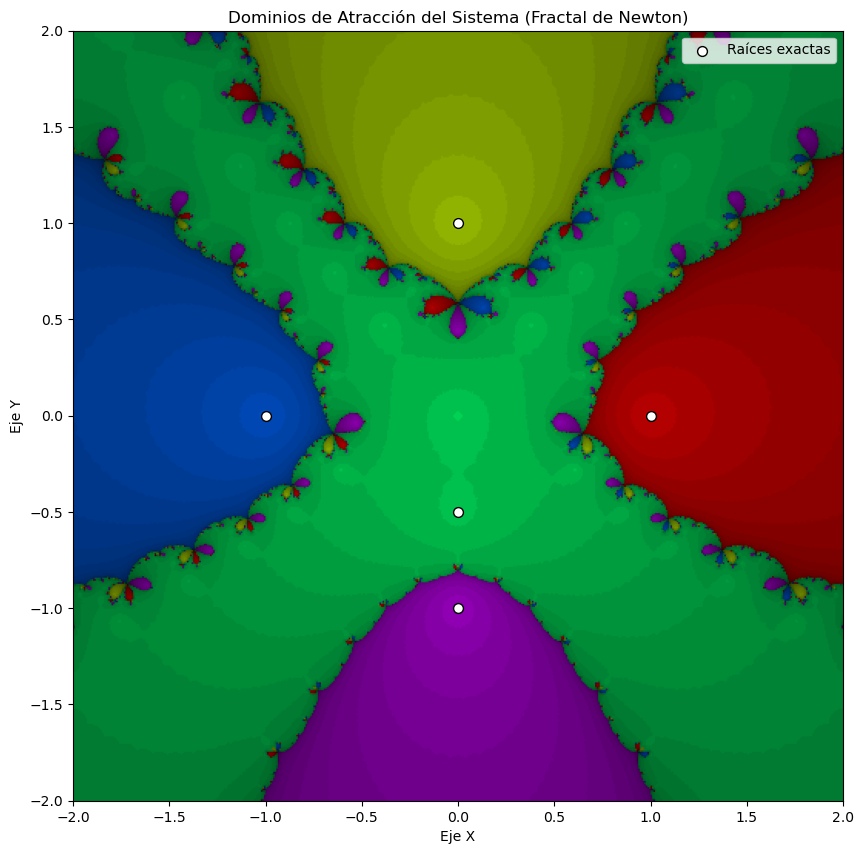

In [9]:
# Creamos una imagen vacía en formato HSV (Hue, Saturation, Value)
imagen_hsv = np.zeros((resolucion, resolucion, 3))

# Definimos 5 colores base (Hue) para identificar las diferentes raíces a las que van los puntos
colores_base = np.linspace(0, 0.8, 5)

# Normalizamos las iteraciones para usarlas en el tono (brillo), a más iteraciones, más oscuro
iter_maximas_alcanzadas = np.max(mapa_iteraciones)

for i in range(resolucion):
    for j in range(resolucion):
        indice = mapa_raices[i, j]
        iteraciones = mapa_iteraciones[i, j]
        
        if indice != -1:
            # Hue: El color asignado a la raíz
            imagen_hsv[i, j, 0] = colores_base[indice]
            # Saturation: Saturación al máximo para que los colores sean vivos
            imagen_hsv[i, j, 1] = 1.0
            # Value: Uniformemente asignamos menos brillo cuantas más iteraciones tarda
            brillo = 1.0 - (iteraciones / iter_maximas_alcanzadas)**0.5 
            # Nos aseguramos de que no sea completamente negro (mínimo 0.2)
            imagen_hsv[i, j, 2] = max(0.2, brillo)
        else:
            # Si diverge, lo pintamos de negro
            imagen_hsv[i, j, :] = [0, 0, 0]

# Convertimos de HSV a RGB para que matplotlib pueda dibujarlo
imagen_rgb = hsv_to_rgb(imagen_hsv)

# Dibujamos el resultado final
plt.figure(figsize=(10, 10))
plt.title("Dominios de Atracción del Sistema (Fractal de Newton)")
plt.imshow(imagen_rgb, extent=[x_min, x_max, y_min, y_max])
plt.xlabel("Eje X")
plt.ylabel("Eje Y")

# Dibujamos encima las 5 raíces exactas como puntos blancos para ubicarlas
plt.scatter(raices_exactas[:, 0], raices_exactas[:, 1], color='white', edgecolor='black', s=50, zorder=5, label="Raíces exactas")
plt.legend(loc="upper right")

plt.show()

## 4. Aportes extra

### 4.1. Análisis de la Velocidad de Convergencia (Mapa de Calor)

En esta primera sección extra de la práctica, profundizamos en el rendimiento del método de Newton-Raphson. Aprovechando los datos almacenados durante la generación de los dominios de atracción, hemos construido un mapa de calor de las iteraciones. 

Aislamos la variable velocidad de convergencia para estudiar visualmente la sensibilidad a las condiciones iniciales. Al utilizar una escala de color secuencial, podremos identificar fácilmente las regiones del plano donde el sistema está bien condicionado frente a las zonas de inestabilidad geométrica.

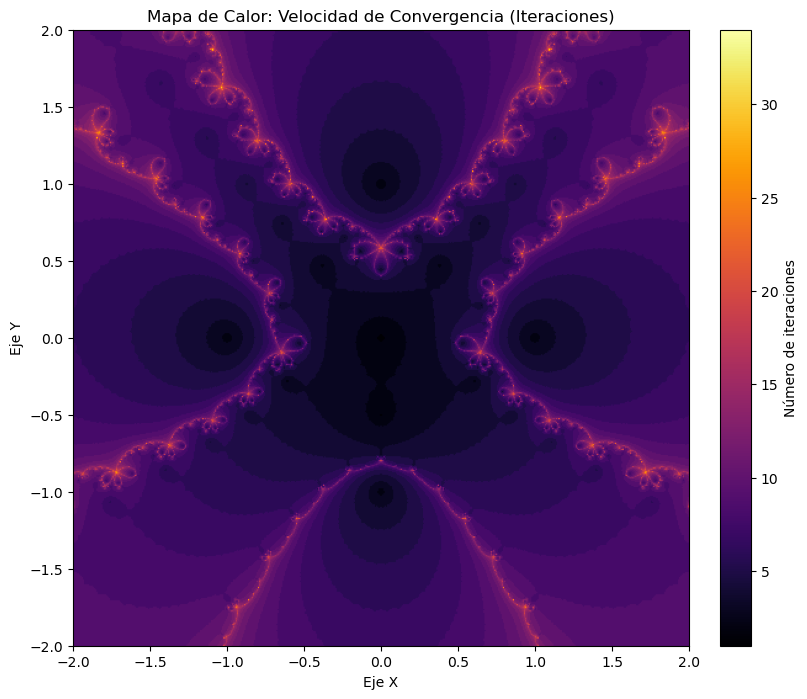

In [10]:
plt.figure(figsize=(10, 8))
plt.title("Mapa de Calor: Velocidad de Convergencia (Iteraciones)")

# Usamos la matriz 'mapa_iteraciones' que ya calculamos en la Fase 3.
# El colormap 'inferno' o 'hot' representa valores bajos con colores oscuros 
# y valores altos (muchas iteraciones) con colores brillantes/claros.
imagen_calor = plt.imshow(mapa_iteraciones, extent=[x_min, x_max, y_min, y_max], cmap='inferno')

# Añadimos una barra de color lateral para visualizar la escala
barra = plt.colorbar(imagen_calor, fraction=0.046, pad=0.04)
barra.set_label('Número de iteraciones')

plt.xlabel("Eje X")
plt.ylabel("Eje Y")

plt.show()

Al observar el mapa de calor generado, podemos extraer conclusiones directas sobre el comportamiento numérico del sistema:

- Zonas oscuras (Bajas iteraciones): representan los núcleos o zonas de atracción de los puntos a las soluciones. Al inicializar el algoritmo en estas áreas, la matriz Jacobiana está perfectamente condicionada y orientada hacia la raíz. El método aprovecha su convergencia cuadrática y resuelve el sistema lineal en menos de 10 pasos.
- Fronteras brillantes (Altas iteraciones): las líneas de colores cálidos y amarillos coinciden de manera exacta con las fronteras fractales que separan los dominios. En estas regiones el sistema es altamente sensible, el Jacobiano sufre cambios bruscos y el algoritmo da múltiples saltos por todo el plano, acercándose a nuestro límite de iteraciones de seguridad antes de encontrar el camino final hacia una de las raíces.

### 4.2. Visualización de la Trayectoria

Ya vistas las visiones más globales de los fractales y mapa de calor, nos vamos a centrar en un ejemplo más local de alguna de las soluciones.

Hemos implementado una variante del algoritmo que almacena en memoria cada punto intermedio calculado ($X_0, X_1, X_2...$) para trazar ese camino iterativo desde una aproximación inicial hasta converger a una de las soluciones. 

Para ilustrar la drástica sensibilidad a las condiciones iniciales, comparamos dos trayectorias sobre las curvas implícitas:
* Una desde un punto en una zona bien condicionada, que debería mostrar un camino directo.
* Otra desde un punto en una zona fronteriza o inestable, para visualizar los saltos que da el algoritmo antes de lograr la convergencia.

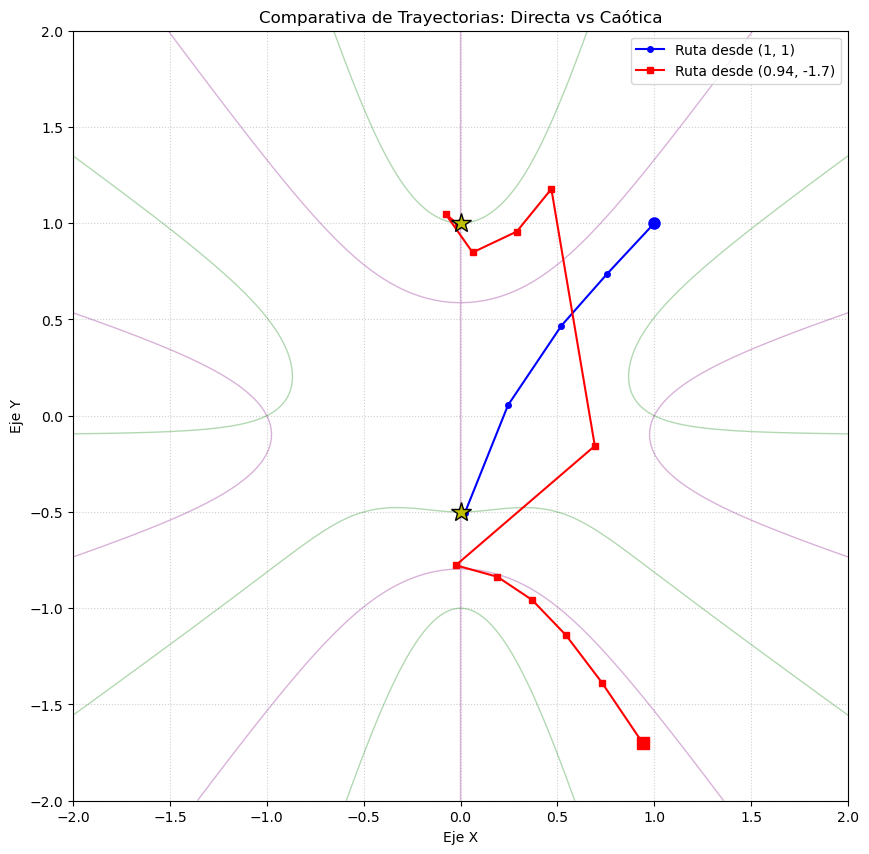

In [11]:
def newton_raphson_trayectoria(x0, y0, tol=1e-5, max_iter=50):
    X = np.array([x0, y0], dtype=float)
    trayectoria = [X.copy()] # Guardamos el punto inicial
    
    for i in range(max_iter):
        x, y = X[0], X[1]
        F = np.array([f(x, y), g(x, y)])
        
        if np.linalg.norm(F, np.inf) < tol:
            break
            
        J = jacobiano(x, y)
        try:
            dX = np.linalg.solve(J, -F)
        except np.linalg.LinAlgError:
            break
            
        X = X + dX
        trayectoria.append(X.copy()) # Guardamos el nuevo punto tras el salto
        
        if np.linalg.norm(dX, np.inf) < tol:
            break
            
    return np.array(trayectoria)

# Calculamos las trayectorias para dos puntos con comportamientos muy distintos
punto_directo = (1, 1)           # Suele converger rápido sin muchos desvíos
punto_caotico = (0.94, -1.7)     # Punto conflictivo que dará saltos

camino_directo = newton_raphson_trayectoria(punto_directo[0], punto_directo[1])
camino_caotico = newton_raphson_trayectoria(punto_caotico[0], punto_caotico[1])

#Dibujamos las curvas originales y ambas trayectorias
plt.figure(figsize=(10, 10))
plt.title("Comparativa de Trayectorias: Directa vs Caótica")

# Redibujamos las curvas menos resaltadas
plt.contour(X, Y, F_vals, levels=[0], colors='purple', linewidths=1.0, alpha=0.3)
plt.contour(X, Y, G_vals, levels=[0], colors='green', linewidths=1.0, alpha=0.3)

# Dibujamos la trayectoria rápida/directa (Azul)
plt.plot(camino_directo[:, 0], camino_directo[:, 1], color='blue', marker='o', linestyle='-', linewidth=1.5, markersize=4, label=f'Ruta desde {punto_directo}')
plt.plot(camino_directo[0, 0], camino_directo[0, 1], 'bo', markersize=8) # Inicio azul

# Dibujamos la trayectoria larga/caótica (Rojo)
plt.plot(camino_caotico[:, 0], camino_caotico[:, 1], color='red', marker='s', linestyle='-', linewidth=1.5, markersize=4, label=f'Ruta desde {punto_caotico}')
plt.plot(camino_caotico[0, 0], camino_caotico[0, 1], 'rs', markersize=8) # Inicio rojo

# Resaltamos las raíces finales alcanzadas (Estrellas)
plt.plot(camino_directo[-1, 0], camino_directo[-1, 1], 'y*', markersize=15, markeredgecolor='black', zorder=5)
plt.plot(camino_caotico[-1, 0], camino_caotico[-1, 1], 'y*', markersize=15, markeredgecolor='black', zorder=5)

# Detalles estéticos de la gráfica
plt.xlim([-2, 2])
plt.ylim([-2, 2])
plt.grid(True, linestyle=':', alpha=0.6)
plt.xlabel("Eje X")
plt.ylabel("Eje Y")
plt.legend()

plt.show()

* **Trayectoria Azul (Ruta Directa):** Iniciando en el punto $(1, 1)$, el algoritmo se encuentra en una región del plano donde las funciones son suaves y la matriz Jacobiana está bien condicionada. Esto permite que el método realice una aproximación casi rectilínea, acortando la longitud de los pasos gradualmente gracias a la convergencia cuadrática, hasta anclarse en la raíz $(0, -0.5)$.
* **Trayectoria Roja (Ruta Caótica):** El punto inicial $(0.94, -1.7)$ se sitúa en una zona fronteriza de alta inestabilidad. A pesar de tener la raíz $(0, -1)$ muy cerca geográficamente, tras las primeras iteraciones el algoritmo provoca una serie de saltos sin orden y bruscos: cruza el plano de abajo a arriba, rebotando por distintos cuadrantes hasta caer finalmente en el dominio de atracción de la raíz superior $(0, 1)$, ubicada muy lejos opuesto del punto inicial.

### 4.3. Zoom en la Frontera

Para poder ver mejor cómo se comportan los dominios de atracción generados por el método de Newton-Raphson, hemos implementado una ampliación de este para estudiarlo. 

En los sistemas no lineales, las fronteras que separan las distintas zonas de atracción no son son curvas suaves ni bien definidas, presentan una estructura fractal. Para ilustrarlo este hemos recalculado la matriz de convergencia restringiendo los límites de la malla a una pequeña ventana ubicada entre las raíces inferiores.

Generando el zoom del fractal...



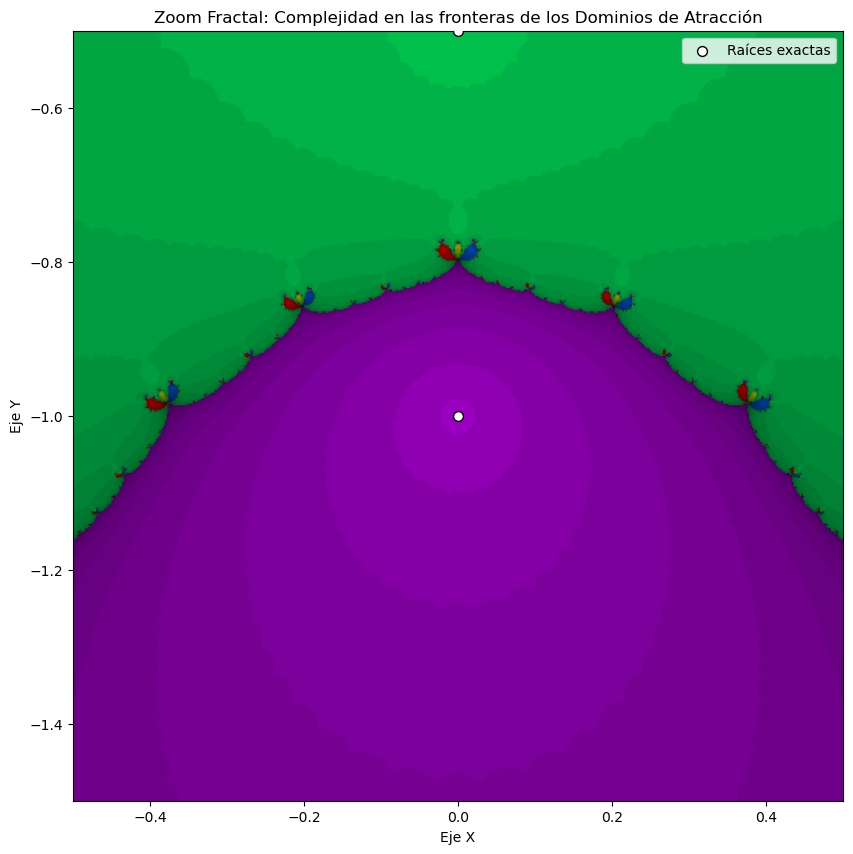

In [12]:
 # Puede tardar un poco al igual que antes. (Debe desaparecer * de In [*] y poner [20])
print("Generando el zoom del fractal...\n")

# 1. Definimos los NUEVOS límites para hacer zoom en una zona caótica
# Por ejemplo, una zona fronteriza entre las raíces inferiores
zoom_x_min, zoom_x_max = -0.5, 0.5
zoom_y_min, zoom_y_max = -1.5, -0.5
resolucion_zoom = 500 # Mantenemos una resolución alta para ver el detalle

# Matrices para el nuevo fractal
zoom_mapa_raices = np.zeros((resolucion_zoom, resolucion_zoom), dtype=int)
zoom_mapa_iteraciones = np.zeros((resolucion_zoom, resolucion_zoom), dtype=int)

# Nuevos ejes
zoom_x_vals = np.linspace(zoom_x_min, zoom_x_max, resolucion_zoom)
zoom_y_vals = np.linspace(zoom_y_max, zoom_y_min, resolucion_zoom)

# Bucle de cálculo masivo para la nueva ventana
for i in range(resolucion_zoom):
    for j in range(resolucion_zoom):
        x0 = zoom_x_vals[j]
        y0 = zoom_y_vals[i]
        
        raiz_encontrada, num_iter = newton_raphson_sistema(x0, y0, tol=1e-5, max_iter=40)
        indice_raiz = clasificar_raiz(raiz_encontrada, raices_exactas)
        
        zoom_mapa_raices[i, j] = indice_raiz
        zoom_mapa_iteraciones[i, j] = num_iter

# Renderizado de la nueva imagen
zoom_imagen_hsv = np.zeros((resolucion_zoom, resolucion_zoom, 3))
iter_maximas_zoom = np.max(zoom_mapa_iteraciones)

for i in range(resolucion_zoom):
    for j in range(resolucion_zoom):
        indice = zoom_mapa_raices[i, j]
        iteraciones = zoom_mapa_iteraciones[i, j]
        
        if indice != -1:
            zoom_imagen_hsv[i, j, 0] = colores_base[indice]
            zoom_imagen_hsv[i, j, 1] = 1.0
            brillo = 1.0 - (iteraciones / iter_maximas_zoom)**0.5
            zoom_imagen_hsv[i, j, 2] = max(0.2, brillo)
        else:
            zoom_imagen_hsv[i, j, :] = [0, 0, 0]

zoom_imagen_rgb = hsv_to_rgb(zoom_imagen_hsv)

# Dibujamos el resultado
plt.figure(figsize=(10, 10))
plt.title("Zoom Fractal: Complejidad en las fronteras de los Dominios de Atracción")
plt.imshow(zoom_imagen_rgb, extent=[zoom_x_min, zoom_x_max, zoom_y_min, zoom_y_max])
plt.xlabel("Eje X")
plt.ylabel("Eje Y")

# Dibujamos las raíces exactas (solo aparecerán las que caigan dentro de nuestra nueva ventana)
plt.scatter(raices_exactas[:, 0], raices_exactas[:, 1], color='white', edgecolor='black', s=50, zorder=5, label="Raíces exactas")

# Ajustamos los límites visuales
plt.xlim([zoom_x_min, zoom_x_max])
plt.ylim([zoom_y_min, zoom_y_max])
plt.legend(loc="upper right")

plt.show()

* **Fronteras:** Los colores no están separados por líneas simples, sino que se observan bucles, salientes irregulares que se entrelazan. En estas zonas límite es imposible predecir a qué solución convergerá un punto inicial sin ejecutar el algoritmo completo. Dos puntos separados por una distancia minúscula (píxeles adyacentes en nuestra malla) pueden terminar en soluciones totalmente opuestas (En el apartado anterior, cambiar la coordenada x del punto caótico 0.94 por 0.95 cambia totalmente la raíz a la que converge el punto inicial).
* **Relación con el número de iteraciones:** Las zonas más enredadas del fractal coinciden con un menor brillo de la imagen, mostrando que la frontera actúa como una zona peligrosa para el Jacobiano, obligando al algoritmo iterativo a realizar un número elevado de cálculos (zonas oscuras) antes de lograr llegar hacia un dominio estable.

### 4.4. Análisis del Fractal  ($z^3 - 1 = 0$)

Para complementar el estudio de los dominios de atracción hemos decidido intentar replicar el problema que estudiamos en clase. Para ilustrar la dificultad de determinar el dominio de atracción de una raíz, vimos como ejemplo el cálculo de las soluciones de la ecuación compleja $z^3 - 1 = 0$.

Nuestro objetivo es demostrar que el algoritmo iterativo bidimensional que hemos implementado es capaz de producir este mismo resultado. Primero debemos adaptar el problema descomponiendo la variable compleja $z = x + iy$. Desarrollando el binomio al cubo e igualando a cero, obtenemos el siguiente sistema equivalente de ecuaciones no lineales en $\mathbb{R}^2$:

* $f(x,y) = x^3 - 3xy^2 - 1 = 0$
* $g(x,y) = 3x^2y - y^3 = 0$

Este sistema posee exactamente tres soluciones (las raíces cúbicas de la unidad), situadas en $z_1 = 1$, $z_2 = -0.5 + i\frac{\sqrt{3}}{2}$ y $z_3 = -0.5 - i\frac{\sqrt{3}}{2}$.

Generando el fractal de z^3 - 1...



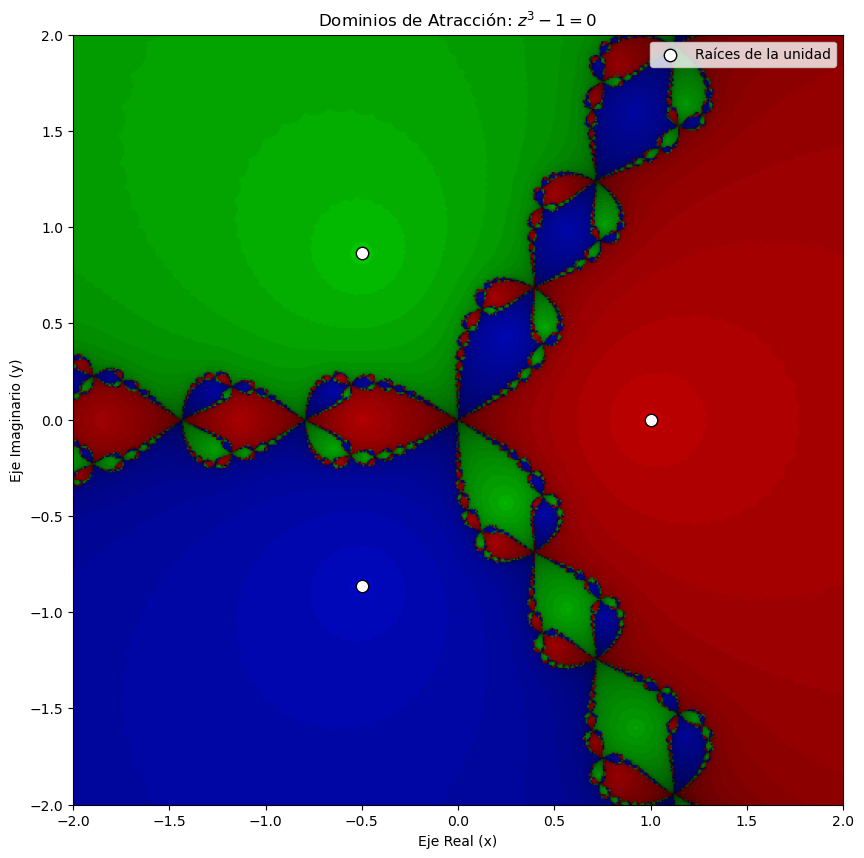

In [13]:
print("Generando el fractal de z^3 - 1...\n")

# 1. Definimos las nuevas funciones y el Jacobiano analítico
def cub_f(x, y):
    return x**3 - 3*x*y**2 - 1

def cub_g(x, y):
    return 3*x**2*y - y**3

def cub_jacobiano(x, y):
    dfdx = 3*x**2 - 3*y**2
    dfdy = -6*x*y
    dgdx = 6*x*y
    dgdy = 3*x**2 - 3*y**2
    return np.array([[dfdx, dfdy], [dgdx, dgdy]])

# Adaptamos el método de Newton

def cub_newton_raphson(x0, y0, tol=1e-5, max_iter=40):
    X = np.array([x0, y0], dtype=float)
    for i in range(max_iter):
        x, y = X[0], X[1]
        F = np.array([cub_f(x, y), cub_g(x, y)])
        if np.linalg.norm(F, np.inf) < tol:
            return X, i
            
        J = cub_jacobiano(x, y)
        try:
            dX = np.linalg.solve(J, -F)
        except np.linalg.LinAlgError:
            return None, i
            
        X = X + dX
        if np.linalg.norm(dX, np.inf) < tol:
            return X, i
    return X, max_iter

# Guardamos las 3 raíces exactas del sistema manualmente
raices_cubicas = np.array([
    [1.0, 0.0],
    [-0.5, np.sqrt(3)/2],
    [-0.5, -np.sqrt(3)/2]
])

# Preparamos la malla de la imagen
res_cub = 500
lim_cub = 2.0
x_c = np.linspace(-lim_cub, lim_cub, res_cub)
y_c = np.linspace(lim_cub, -lim_cub, res_cub) # Invertido para imshow

mapa_raices_cub = np.zeros((res_cub, res_cub), dtype=int)
mapa_iter_cub = np.zeros((res_cub, res_cub), dtype=int)

# Ejecución del método en cada punto
for i in range(res_cub):
    for j in range(res_cub):
        raiz_enc, iters = cub_newton_raphson(x_c[j], y_c[i])
        
        # Clasificamos comprobando distancias
        if raiz_enc is not None:
            dist = np.linalg.norm(raices_cubicas - raiz_enc, axis=1)
            idx_raiz = np.argmin(dist)
            if dist[idx_raiz] < 1e-3:
                mapa_raices_cub[i, j] = idx_raiz
            else:
                mapa_raices_cub[i, j] = -1
        else:
            mapa_raices_cub[i, j] = -1
            
        mapa_iter_cub[i, j] = iters

# Renderizado de colores (3 colores en lugar de 5)
img_hsv_cub = np.zeros((res_cub, res_cub, 3))
colores_cub = np.linspace(0, 0.66, 3)
max_iter_cub = np.max(mapa_iter_cub)

for i in range(res_cub):
    for j in range(res_cub):
        idx = mapa_raices_cub[i, j]
        iters = mapa_iter_cub[i, j]
        
        if idx != -1:
            img_hsv_cub[i, j, 0] = colores_cub[idx]
            img_hsv_cub[i, j, 1] = 1.0
            # Oscurecemos según las iteraciones
            img_hsv_cub[i, j, 2] = max(0.2, 1.0 - (iters / max_iter_cub)**0.5)
        else:
            img_hsv_cub[i, j, :] = [0, 0, 0]

img_rgb_cub = hsv_to_rgb(img_hsv_cub)

#Dibujo final
plt.figure(figsize=(10, 10))
plt.title("Dominios de Atracción: $z^3 - 1 = 0$")
plt.imshow(img_rgb_cub, extent=[-lim_cub, lim_cub, -lim_cub, lim_cub])
plt.scatter(raices_cubicas[:, 0], raices_cubicas[:, 1], c='white', edgecolor='black', s=80, zorder=5, label='Raíces de la unidad')
plt.xlabel("Eje Real (x)")
plt.ylabel("Eje Imaginario (y)")
plt.legend(loc="upper right")
plt.show()


**Interpretación de los Resultados:**

La ejecución de nuestro código confirma que la implementación del método de Newton-Raphson es totalmente correcta, ya que el gráfico generado coincide con la imagen de las cuencas de atracción estudiada en las diapositivas. 

* **División de dominios:** el plano complejo queda dividido de forma simétrica en tres zonas de color distintas, correspondiendo cada una al dominio de atracción de una de las tres raíces de la ecuación.
* **Velocidad de convergencia:** el tono que refleja correctamente la velocidad de convergencia, oscureciendo las zonas donde se requiere un mayor número de iteraciones para alcanzar la raíz.
* **Frontera:** se reproduce la forma enredada de las zonas límites En estas franjas oscuras, la matriz Jacobiana es inestable y el algoritmo se ve obligado a dar múltiples saltos como hemos explicado anteriormente.

### 4.5. Raíces Múltiples

El guion de la práctica sugiere valorar qué ocurriría con el método si el sistema presentara soluciones dobles. Teóricamente, la convergencia del método de Newton-Raphson está garantizada como cuadrática siempre que la matriz Jacobiana sea no singular en la raíz (es decir, $det(J) \neq 0$). Sin embargo, en una raíz doble o múltiple, las curvas no se cruzan transversalmente, sino que son tangentes, lo que provoca que el Jacobiano se anule en dicho punto y el método pierda su eficacia.

Para visualizar este fenómeno, hemos implementado el siguiente sistema geométrico:
* $f(x,y) = x^2 + y^2 - 2y = 0$    (Una circunferencia de radio 1 centrada en $(0,1)$).
* $g(x,y) = x^2 + y = 0$           (Una parábola invertida).

Ambas curvas son tangentes en el origen $(0,0)$, convirtiéndolo en una raíz doble. El determinante de su Jacobiano es $det(J) = 6x - 4xy$. Veamos el mapa de calor de las iteraciones ampliando $X, Y \in [-4, 4]$ para estudiar cómo esta singularidad afecta a la convergencia global del plano.

Generando mapa de calor de la raíz doble...


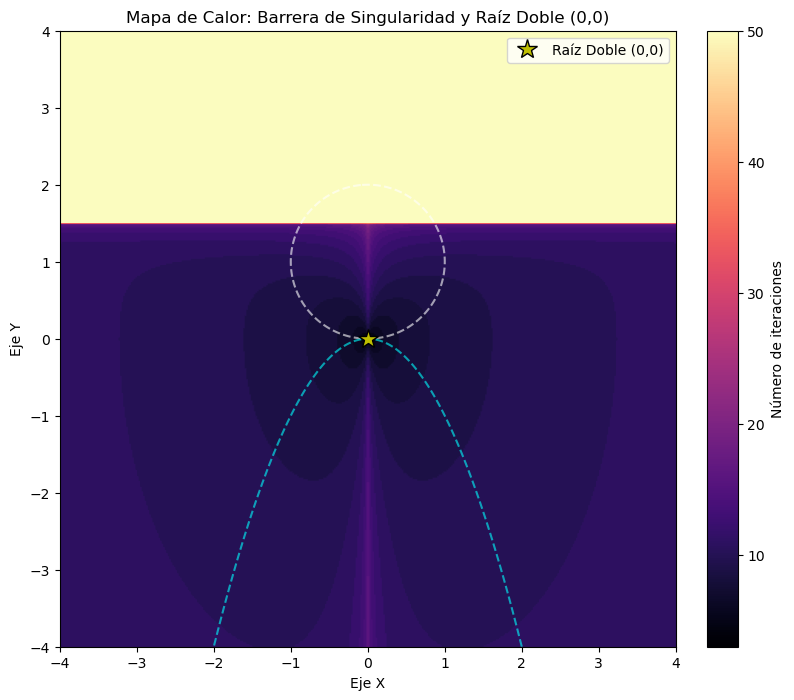

In [14]:
print("Generando mapa de calor de la raíz doble...")

# Definimos las funciones del sistema
def circunf(x, y):
    return x**2 + y**2 - 2*y

def parab(x, y):
    return x**2 + y

def doble_jacobiano(x, y):
    return np.array([
        [2*x, 2*y - 2],
        [2*x, 1]
    ])

# Implementación del método de Newton-Raphson adaptado
def doble_newton_raphson(x0, y0, tol=1e-5, max_iter=50):
    X = np.array([x0, y0], dtype=float)
    for i in range(max_iter):
        x, y = X[0], X[1]
        F = np.array([circunf(x, y), parab(x, y)])
        if np.linalg.norm(F, np.inf) < tol:
            return X, i
            
        J = doble_jacobiano(x, y)
        try:
            dX = np.linalg.solve(J, -F)
        except np.linalg.LinAlgError:
            return None, max_iter # Si es singular, forzamos el máximo de iteraciones visual
            
        X = X + dX
        if np.linalg.norm(dX, np.inf) < tol:
            return X, i
    return X, max_iter

# Preparamos la malla
res_doble = 400
lim_doble = 4.0
x_doble = np.linspace(-lim_doble, lim_doble, res_doble)
y_doble = np.linspace(lim_doble, -lim_doble, res_doble)

mapa_iter_doble = np.zeros((res_doble, res_doble), dtype=int)

# Cálculo de iteraciones
for i in range(res_doble):
    for j in range(res_doble):
        _, iters = doble_newton_raphson(x_doble[j], y_doble[i])
        mapa_iter_doble[i, j] = iters

# Dibujo del mapa de calor
plt.figure(figsize=(10, 8))
plt.title("Mapa de Calor: Barrera de Singularidad y Raíz Doble (0,0)")

# Dibujamos las curvas originales
X_m, Y_m = np.meshgrid(x_doble, y_doble)
plt.contour(X_m, Y_m, circunf(X_m, Y_m), levels=[0], colors='white', linewidths=1.5, alpha=0.6, linestyles='dashed')
plt.contour(X_m, Y_m, parab(X_m, Y_m), levels=[0], colors='cyan', linewidths=1.5, alpha=0.6, linestyles='dashed')

# Mostramos el mapa de iteraciones
img_calor_doble = plt.imshow(mapa_iter_doble, extent=[-lim_doble, lim_doble, -lim_doble, lim_doble], cmap='magma')
barra_doble = plt.colorbar(img_calor_doble, fraction=0.046, pad=0.04)
barra_doble.set_label('Número de iteraciones')

# Marcamos la raíz doble
plt.plot(0, 0, 'y*', markersize=15, markeredgecolor='black', label="Raíz Doble (0,0)")

plt.xlabel("Eje X")
plt.ylabel("Eje Y")
plt.legend(loc="upper right")
plt.show()

* **Franja de singularidad:** El rasgo más llamativo de la imagen es la zona amarilla que domina toda la mitad superior del plano a partir de la altura $y = 1.5$. Esto no es un error sino una barrera inevitable en nuestro ejemplo. Si factorizamos el determinante del Jacobiano, obtenemos $\det(J) = 2x(3 - 2y)$. Esto demuestra que la matriz se vuelve singular en dos lugares geométricos: en el eje $x=0$ y en la recta horizontal $y=1.5$. Si inicializamos el algoritmo por encima de esa recta, el método es incapaz de cruzar esa barrera de singularidad para alcanzar la raíz, entrando en un bucle infinito que agota las iteraciones (color amarillo).
* **Raíz doble:** en las raíces simples, el entorno cercano converge casi al instante en 1 o 2 pasos, en este caso el origen $(0,0)$ aparece rodeado de una zona oscura que se prolonga a lo largo del eje Y (donde $\det(J)=0$). En esta zona, el método pierde su convergencia cuadrática y se vuelve extremadamente lento o inestable al acercarse al punto de tangencia entre las dos figuras.

## 5.Referencias

### 5.1. Herramientas de Inteligencia Artificial

Google Gemini (2026). Asistencia en la optimización de código, modularización de funciones y refinamiento de visualización de datos con Matplotlib. Esta herramienta se utilizó para la depuración del algoritmo de Newton-Raphson y el ajuste de los ejes cartesianos en la representación del fractal de Newton.

### 5.2. Teoría de la asignatura

Apuntes de la asignatura: Métodos Numéricos II. Material docente del curso, concretamente, el Tema 1 sobre "Resolucion numérica de ecuaciones y sistemas no lineales". Se aplicaron los fundamentos teóricos del Método de Newton-Raphson y el cálculo de la matriz Jacobiana para la resolución del sistema planteado.

### 5.3. Libro de referencia técnica
Burden, R. L., & Faires, J. D. (2011). Análisis Numérico. Cengage Learning.

Este libro es el estándar. De aquí se extrae la lógica de cómo implementar el bucle iterativo de Newton y cómo tratar el Jacobiano en lenguajes de programación.
